# OOVIRI – partea P1: adâncime în metri și ruta C

Rulează cele 3 modele (Depth Anything V2, MiDaS, ZoeDepth) și ruta C (mediana per pixel) pe imagini NYU. Lângă `<id>.png` stă `<id>_depth.png` (adevărul NYU, uint16 în mm): DA V2 și MiDaS se aliniază pe el. Pe fotografii proprii (fără `_depth.png`) se aliniază pe ZoeDepth.

Ieșire în `outputs/`: `<id>_<metodă>.npy` (metri), `<id>_<metodă>.png`, `<id>_panel.png`.

Înainte: `python scripts/download_nyu.py` (o singură dată).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, "..")
from depth.run import process

IMAGES = Path("../data/nyu_test")  # folderul cu imagini
IDS = ["0003", "0036"]            # ce imagini rulăm
OUT = Path("../outputs")

## 1. Cele 3 modele + ruta C

AbsRel (mai mic e mai bine) pe fiecare imagine, în crop-ul Eigen.

In [2]:
paths = [IMAGES / f"{i}.png" for i in IDS]
for p in paths:
    scores = process(p, OUT)
    print(p.name, "  ".join(f"{m}: {s:.3f}" for m, s in scores.items()))

Loading weights:   0%|          | 0/647 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/458 [00:00<?, ?it/s]

[transformers] DPTForDepthEstimation LOAD REPORT from: Intel/dpt-large
Key                                                            | Status  | 
---------------------------------------------------------------+---------+-
neck.fusion_stage.layers.0.residual_layer1.convolution2.bias   | MISSING | 
neck.fusion_stage.layers.0.residual_layer1.convolution2.weight | MISSING | 
neck.fusion_stage.layers.0.residual_layer1.convolution1.weight | MISSING | 
neck.fusion_stage.layers.0.residual_layer1.convolution1.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


0003.png depth_anything_v2: 0.073  midas: 0.103  zoedepth: 0.267  ruta_C: 0.080


0036.png depth_anything_v2: 0.061  midas: 0.054  zoedepth: 0.060  ruta_C: 0.051


## 2. Panourile

Albastru = aproape, roșu = departe; aceeași scală de culori în tot panoul.

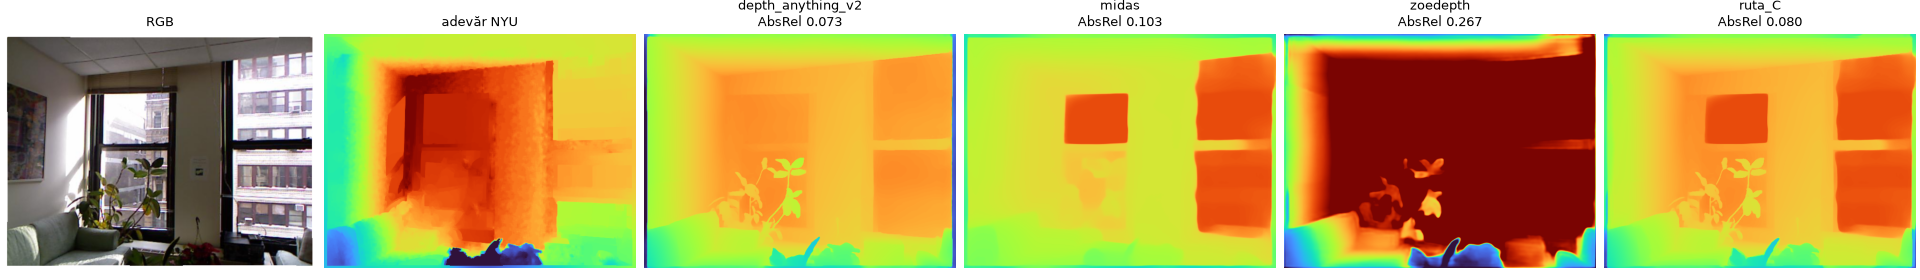

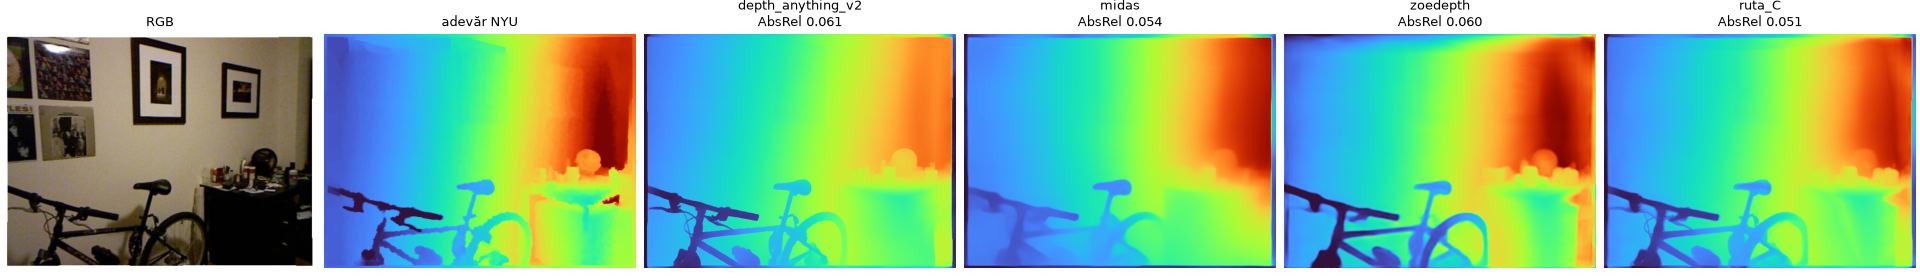

In [3]:
from IPython.display import Image, display

for p in paths:
    display(Image(filename=OUT / f"{p.stem}_panel.png"))

## 3. O hartă în metri, comparată cu adevărul

`METODA`: `depth_anything_v2`, `midas`, `zoedepth` sau `ruta_C`.

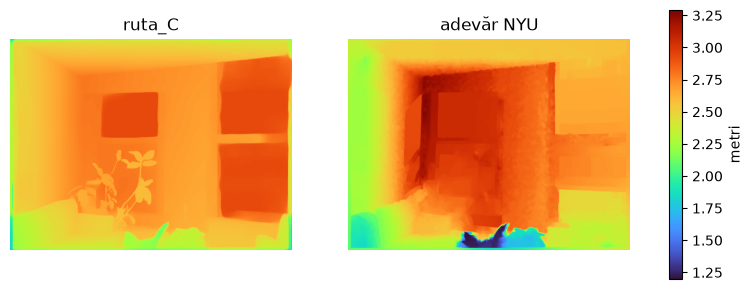

pixelul (240, 320): ruta_C = 2.76 m, adevăr = 3.03 m


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from depth.run import load_gt

METODA = "ruta_C"
ID = IDS[0]

d = np.load(OUT / f"{ID}_{METODA}.npy")
gt = load_gt(IMAGES / f"{ID}.png")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (titlu, harta) in zip(axes, [(METODA, d), ("adevăr NYU", gt)]):
    im = ax.imshow(harta, cmap="turbo", vmin=gt.min(), vmax=gt.max())
    ax.set_title(titlu)
    ax.axis("off")
fig.colorbar(im, ax=axes, label="metri")
plt.show()

r, c = 240, 320  # pixelul din centru
print(f"pixelul ({r}, {c}): {METODA} = {d[r, c]:.2f} m, adevăr = {gt[r, c]:.2f} m")

## 4. Evaluarea pe setul de test

AbsRel, RMSE, δ1 și timpul pe imagine, pentru fiecare model și ruta C, cu aliniere pe adevăr (`gt`) și pe ZoeDepth. `N = 654` rulează tot setul (~2 minute pe GPU); aici un subset, pentru viteză.

In [5]:
import csv
import subprocess

N = 50
subprocess.run([sys.executable, "-m", "evaluation.run", "--n", str(N), "--out", "outputs/eval_depth.csv"],
               cwd="..", capture_output=True, check=True)

with open(OUT / "eval_depth.csv", encoding="utf-8") as f:
    rows = list(csv.reader(f))
for row in rows:
    print("".join(f"{x:<20}" if i < 2 else f"{x:>9}" for i, x in enumerate(row)))

metoda              aliniere               AbsRel     RMSE   delta1    s_img
depth_anything_v2   gt                     0.0992   0.4948   0.9018   0.0239
midas               gt                     0.1180   0.5620   0.8673   0.0437
zoedepth            gt                     0.1038   0.4801   0.9036   0.0877
ruta_C              gt                     0.0903   0.4631   0.9202   0.1553
depth_anything_v2   zoedepth               0.1276   0.5934   0.8480   0.0239
midas               zoedepth               0.1372   0.6101   0.8203   0.0437
zoedepth            zoedepth               0.1038   0.4801   0.9036   0.0877
ruta_C              zoedepth               0.1142   0.5348   0.8793   0.1553
